In [1]:
from pathlib import Path

In [2]:
import matplotlib.pyplot as plt 
import pandas as pd 
import seaborn as sns 

In [3]:
sns.set_theme(style="whitegrid")

In [8]:
DATA_DIR=Path("data")
CHART_DIR=Path("chart")
CHART_DIR.mkdir(exist_ok=True)


In [9]:
orders = pd.read_csv(DATA_DIR / "olist_orders_dataset.csv")
order_items= pd.read_csv(DATA_DIR / "olist_order_items_dataset.csv")
order_payments=pd.read_csv(DATA_DIR / "olist_order_payments_dataset.csv")
customers=pd.read_csv(DATA_DIR / "olist_customers_dataset.csv")
products=pd.read_csv(DATA_DIR / "olist_products_dataset.csv")
product_category_name_translation=pd.read_csv(DATA_DIR /"product_category_name_translation.csv")
order_reviews=pd.read_csv(DATA_DIR /"olist_order_reviews_dataset.csv")
sellers=pd.read_csv(DATA_DIR /"olist_sellers_dataset.csv")
geolocation=pd.read_csv(DATA_DIR /"olist_geolocation_dataset.csv")



In [10]:
print("order :", orders.shape)
print("order items :", order_items.shape )
print("order payments :", order_payments.shape)
orders.head(2)

order : (99441, 8)
order items : (112650, 7)
order payments : (103886, 5)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00


In [12]:
tables = {
    "orders":orders,
    "order_items":order_items,
    "order_payments":order_payments,
    "customers":customers,
    "products":products,
    "order_reviews":order_reviews,
    "sellers":sellers,
    "geolocation":geolocation,

}


for name ,df in tables.items():
    print(f"---{name} {df.shape}---")
    print("duplicate rows:",df.duplicated().sum())
    null=df.isnull().sum()
    print(null[null>0] if null.sum() >0 else "no nulls")
    print()

---orders (99441, 8)---
duplicate rows: 0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

---order_items (112650, 7)---
duplicate rows: 0
no nulls

---order_payments (103886, 5)---
duplicate rows: 0
no nulls

---customers (99441, 5)---
duplicate rows: 0
no nulls

---products (32951, 9)---
duplicate rows: 0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

---order_reviews (99224, 7)---
duplicate rows: 0
review_comment_title      87656
review_comment_message    58247
dtype: int64

---sellers (3095, 4)---
duplicate rows: 0
no nulls

---geolocation (1000163, 5)---
duplicate rows: 261831
no nulls



In [15]:
date_cols =[
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",


]

for col in date_cols:
    orders[col]=pd.to_datetime(orders[col])
orders[date_cols].dtypes

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

In [16]:
# keep only delivered orders that have a delivery date
orders_d = orders[orders["order_status"] == "delivered"].dropna(
    subset=["order_delivered_customer_date"]).copy()

# fix product categories (fill missing, translate to English)
products["product_category_name"] = products["product_category_name"].fillna("unknown")
products = products.merge(product_category_name_translation,
                          on="product_category_name", how="left")
products["product_category_name_english"] = products["product_category_name_english"].fillna("unknown")

# one row per order for payments and reviews
pay = order_payments.groupby("order_id").agg(
    payment_value=("payment_value", "sum"),
    payment_type=("payment_type", "first")).reset_index()
rev = order_reviews.groupby("order_id")["review_score"].mean().reset_index()

# master table
df = (orders_d
      .merge(customers, on="customer_id", how="left")
      .merge(order_items, on="order_id", how="inner")
      .merge(products[["product_id", "product_category_name_english"]], on="product_id", how="left")
      .merge(pay, on="order_id", how="left")
      .merge(rev, on="order_id", how="left"))

print(df.shape)
df.head(3)

(110189, 22)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name_english,payment_value,payment_type,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,3149,...,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,housewares,38.71,credit_card,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,...,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,perfumery,141.46,boleto,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,...,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,auto,179.12,credit_card,5.0


In [17]:
# 1. check the merge worked
print("shape:", df.shape)
print("unique orders:", df["order_id"].nunique())
print(df[["price", "freight_value", "review_score", "product_category_name_english"]].isnull().sum())

# 2. new columns
df["revenue"] = df["price"] + df["freight_value"]
df["order_month"] = df["order_purchase_timestamp"].dt.to_period("M").astype(str)
df["order_year"] = df["order_purchase_timestamp"].dt.year
df["delivery_days"] = (df["order_delivered_customer_date"] - df["order_purchase_timestamp"]).dt.days
df["is_late"] = df["order_delivered_customer_date"] > df["order_estimated_delivery_date"]

df[["revenue", "order_month", "delivery_days", "is_late"]].describe(include="all")

shape: (110189, 22)
unique orders: 96470
price                              0
freight_value                      0
review_score                     827
product_category_name_english      0
dtype: int64


,revenue,order_month,delivery_days,is_late
count,110189.000000,110189,110189.000000,110189
unique,NaN,23,NaN,2
top,NaN,2017-11,NaN,False
freq,NaN,8474,NaN,101475
mean,139.926806,NaN,12.007342,NaN
std,189.324554,NaN,9.451153,NaN
min,6.080000,NaN,0.000000,NaN
25%,55.180000,NaN,6.000000,NaN
50%,92.120000,NaN,10.000000,NaN
75%,157.470000,NaN,15.000000,NaN


## Business Questions
1. How does monthly revenue trend?
2. Which 10 categories earn the most?
3. Which states have the most orders?
4. Which payment types are used?
5. Does late delivery lower review scores?

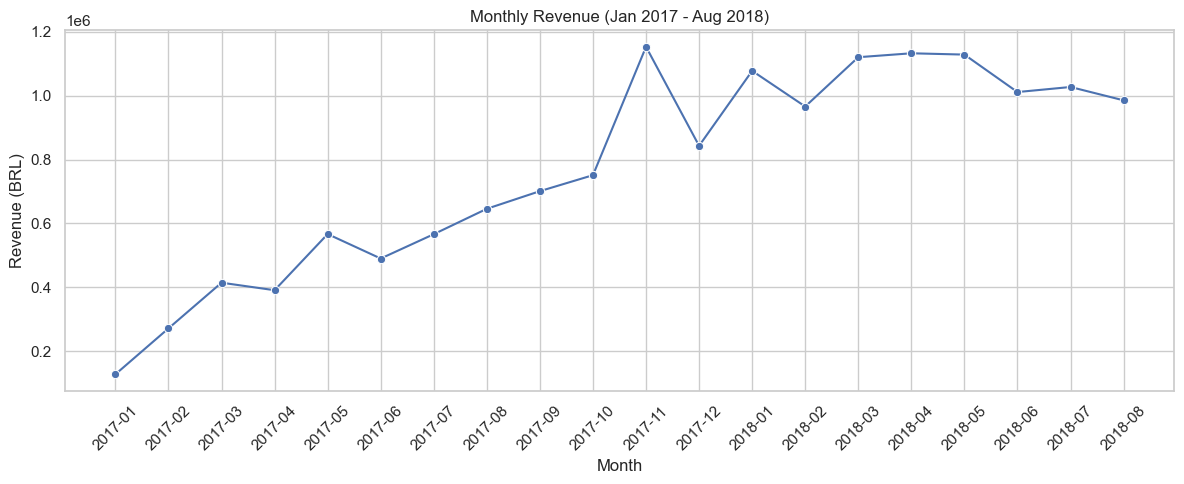

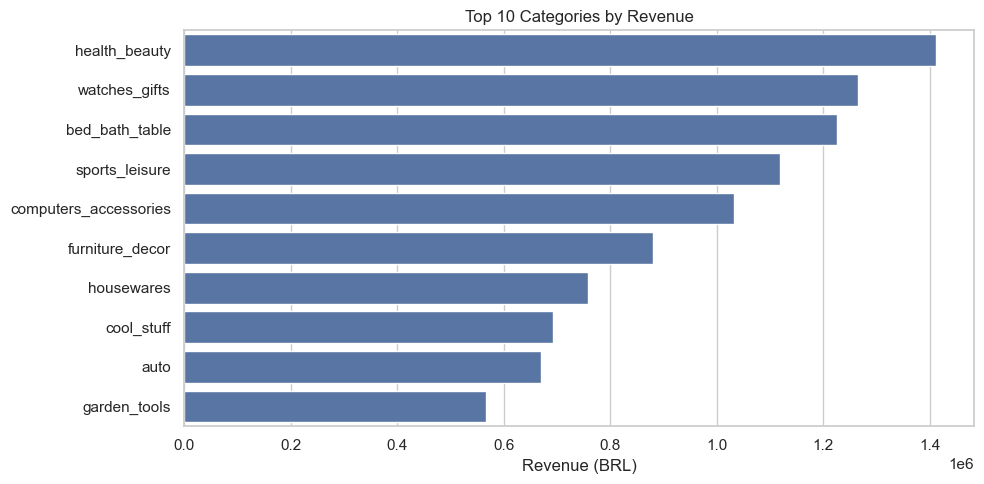

In [18]:
# Chart 1: monthly revenue trend
monthly = df.groupby("order_month")["revenue"].sum().reset_index()
monthly = monthly[(monthly["order_month"] >= "2017-01") & (monthly["order_month"] <= "2018-08")]

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly, x="order_month", y="revenue", marker="o")
plt.xticks(rotation=45)
plt.title("Monthly Revenue (Jan 2017 - Aug 2018)")
plt.xlabel("Month")
plt.ylabel("Revenue (BRL)")
plt.tight_layout()
plt.savefig(CHART_DIR / "01_monthly_revenue.png", dpi=150)
plt.show()

# Chart 2: top 10 categories by revenue
top_cat = (df.groupby("product_category_name_english")["revenue"]
             .sum().sort_values(ascending=False).head(10).reset_index())

plt.figure(figsize=(10, 5))
sns.barplot(data=top_cat, y="product_category_name_english", x="revenue", color="#4c72b0")
plt.title("Top 10 Categories by Revenue")
plt.xlabel("Revenue (BRL)")
plt.ylabel("")
plt.tight_layout()
plt.savefig(CHART_DIR / "02_top_categories.png", dpi=150)
plt.show()

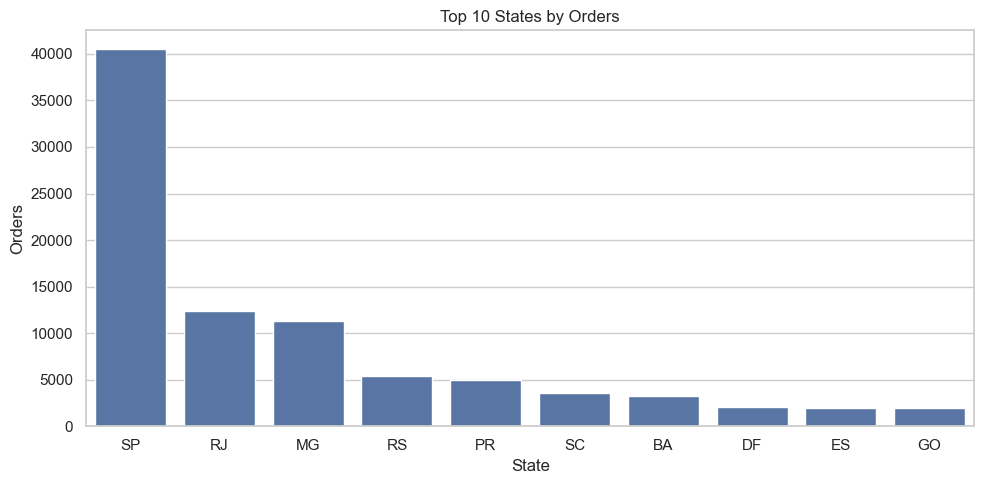

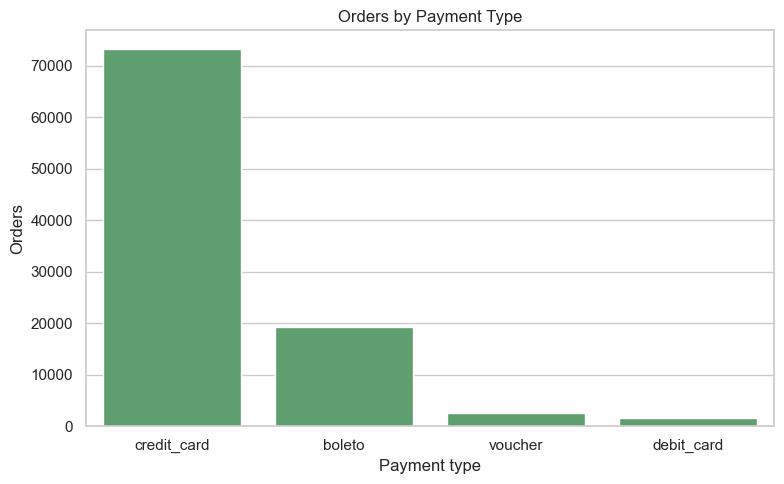

In [19]:
# one row per order (df has one row per item, so orders would be counted twice)
order_level = df.drop_duplicates("order_id")

# Chart 3: top 10 states by number of orders
state = order_level["customer_state"].value_counts().head(10).reset_index()
state.columns = ["state", "orders"]

plt.figure(figsize=(10, 5))
sns.barplot(data=state, x="state", y="orders", color="#4c72b0")
plt.title("Top 10 States by Orders")
plt.xlabel("State")
plt.ylabel("Orders")
plt.tight_layout()
plt.savefig(CHART_DIR / "03_orders_by_state.png", dpi=150)
plt.show()

# Chart 4: payment types
pay_type = order_level["payment_type"].value_counts().reset_index()
pay_type.columns = ["payment_type", "orders"]

plt.figure(figsize=(8, 5))
sns.barplot(data=pay_type, x="payment_type", y="orders", color="#55a868")
plt.title("Orders by Payment Type")
plt.xlabel("Payment type")
plt.ylabel("Orders")
plt.tight_layout()
plt.savefig(CHART_DIR / "04_payment_types.png", dpi=150)
plt.show()

# Chart 5: late

In [20]:
export_cols = [
    "order_id", "order_purchase_timestamp", "order_month", "order_year",
    "customer_state", "customer_city", "product_category_name_english",
    "price", "freight_value", "revenue", "payment_type",
    "review_score", "delivery_days", "is_late",
]

export_df = df[export_cols].copy()
export_df["is_late"] = export_df["is_late"].map({True: "Late", False: "On time"})

export_df.to_csv(DATA_DIR / "clean_olist.csv", index=False)
print(export_df.shape)

(110189, 14)
